# 🎓 STARK ACADEMY — یادگیری تقویتی، قدم‌به‌قدم با آیرون‌من

این نوت‌بوک **آموزشی** است: به‌جای اینکه همه‌چیز را یک‌جا اجرا کنیم، هر مفهوم RL را
در یک سلولِ جدا می‌بینیم — با عددهای واقعی و انیمیشن زنده.

**طرز استفاده:** سلول‌ها را به‌ترتیب از بالا اجرا کن (`Shift+Enter`). هیچ سلولی بیش از چند ثانیه طول نمی‌کشد.

| فصل | چیزی که یاد می‌گیری | ابزار |
|---|---|---|
| ۱ | حلقه‌ی عامل-محیط و پاداش | دیاگرام + محیط پرواز |
| ۲ | جدول Q و معادله‌ی بلمن | به‌روزرسانی با دست، با عدد |
| ۳ | اکتشاف در برابر بهره‌برداری (ε) | برنامه‌ی کاهش ε |
| ۴ | شکل‌گیری مغز در طول آموزش | 🎬 انیمیشن جدول Q |
| ۵ | چندعامله: رادار + پاداش تیمی | 🎬 انیمیشن فلش‌های سیاست |
| ۶ | مأموریت‌های زنده + بازی | HUD + STARK ARCADE |

> 🦾 «Sometimes you gotta run before you can walk.» — Tony Stark

In [1]:
from stark_rl_seminar import *
import numpy as np

banner("🎓 STARK ACADEMY — آماده! (numpy + matplotlib)")
print("هر سلول = یک عملیات. بریم!")


  🎓 STARK ACADEMY — آماده! (numpy + matplotlib)
هر سلول = یک عملیات. بریم!


## 📖 فصل ۱ — داستان: چرا «یادگیری تقویتی»؟

تونی استارک نمی‌تواند برای هر لحظه‌ی پرواز دستور بنویسد — باد 🌪 هر بار از سمتی دیگر می‌آید.
پس به‌جای برنامه‌نویسی مستقیم، به جارویس فقط **یک عدد** می‌دهد: **پاداش**.
بقیه‌اش را خودش با آزمون‌وخطا یاد می‌گیرد.

کل RL در یک تصویر است — این حلقه را در سلول بعد ببین:

In [2]:
print_rl_loop_diagram()


        ┌───────────────────────┐                 ┌───────────────────────┐
        │      🤖 AGENT         │                 │    🌍 ENVIRONMENT      │
        │  (J.A.R.V.I.S / Q)    │                 │  (Suit + Lab + Wind)   │
        └───────────┬───────────┘                 └───────────┬───────────┘
                    │                                         │
                    │   action  aₜ   (fire thruster / hold)    │
                    │  ────────────────────────────────────────▶
                    │                                         │
                    │   state   sₜ₊₁  (new tilt)               │
                    │   reward  rₜ₊₁  (+20 / −2 / −100)        │
                    ◀──────────────────────────────────────── │
                    │                                         │
        ┌───────────┴───────────────────────────────────────────┐
        │  🧠 LEARN:  Q(sₜ,aₜ) ← Q(sₜ,aₜ) + α[rₜ₊₁ + γ·max Q(sₜ₊₁,a)] │
        └─────────────────────────────────

### 🎯 وضعیت (State): کل دنیای زره یک عدد است

محیط پرواز فقط یک عدد نگه می‌دارد: **شیب زره (tilt)** از ‎−۴‎ تا ‎+۴‎.

- `tilt = 0` → 🎯 تعادل کامل (پاداش ‎+۲۰‎)
- `tilt = ±4` → 💥 برخورد با دیوار، پایان اپیزود (پاداش ‎−۱۰۰‎)
- هر وضعیت دیگر → ⛽ هزینه‌ی زمان/سوخت (پاداش ‎−۲‎)

۹ وضعیت ممکن. عامل این عددها را «انتخاب» نمی‌کند — محیط به او می‌گوید کجاست؛ کار عامل فقط انتخاب **اکشن** است.

In [3]:
env1 = StarkFlightBalancerEnv()
s = env1.reset(start_tilt=-3)
print("زره در ارتفاع آزمایشگاه رها شد!  tilt =", s, "  ", tilt_bar(s))
print("دیوارها 💥 یعنی سقوط؛  ✅ یعنی نقطه‌ی تعادل")

زره در ارتفاع آزمایشگاه رها شد!  tilt = -3    💥 🦾 · · ✅ · · · 💥
دیوارها 💥 یعنی سقوط؛  ✅ یعنی نقطه‌ی تعادل


### 🕹 اکشن و پاداش: محیط را دستی تجربه کن

سه اکشن: شلیک رانشگر چپ 🚀 / هیچ‌کاری نکردن 🌪 / شلیک رانشگر راست 🚀.
هر خط پایین یک **انتقال واقعی** محیط است: `(s, a) → (s', r)` — دقیقاً همان چیزی که عامل می‌بیند.

In [4]:
demonstrate_env_steps(env1, actions=(0, 1, 0, 0, 2), start_tilt=-2)


  🕹 محیط را امتحان کنیم — هر خط یک «انتقال» واقعی محیط است:
     شروع: tilt = -2     (پاداش‌ها: 🎯 0° ← +20 | هر گام دیگر ← −2 | 💥 دیوار ← −100)
     گام 1: tilt -2 --FIRE LEFT THRUSTER 🚀    --> tilt -1 | پاداش r =   -2 | 💥 · · 🦾 ✅ · · · 💥
     گام 2: tilt -1 --HOLD (turbulence) 🌪     --> tilt -2 | پاداش r =   -2 | 💥 · 🦾 · ✅ · · · 💥
     گام 3: tilt -2 --FIRE LEFT THRUSTER 🚀    --> tilt -1 | پاداش r =   -2 | 💥 · · 🦾 ✅ · · · 💥
     گام 4: tilt -1 --FIRE LEFT THRUSTER 🚀    --> tilt +0 | پاداش r =  +20 | 💥 · · · 🦾 · · · 💥
     گام 5: tilt +0 --FIRE RIGHT THRUSTER🚀    --> tilt -1 | پاداش r =   -2 | 💥 · · 🦾 ✅ · · · 💥


-1

## 🧠 فصل ۲ — جدول Q: مغز جارویس = ۲۷ عدد

برای هر وضعیت (۹ شیب) و هر اکشن (۳ فرمان) یک عدد نگه می‌داریم:
**«اگر اینجا این کار را بکنم، چقدر پاداش در انتظار من است؟»**

روز اول: همه صفر — جارویس هیچ چیزی نمی‌داند.

In [5]:
pretty_q_table(np.zeros((9, 3)), title="Q-TABLE روز اول — همه صفر")


  🧠 Q-TABLE روز اول — همه صفر   (هر خانه = «چقدر خوب بود این اکشن در این وضعیت؟»)
      tilt  │   ▶ RIGHT   │    • HOLD   │   ◀ LEFT
     ────┼─────────────┼─────────────┼─────────────
     -4   │         +0.0│         +0.0│         +0.0│  💥
     -3   │         +0.0│         +0.0│         +0.0│   
     -2   │         +0.0│         +0.0│         +0.0│   
     -1   │         +0.0│         +0.0│         +0.0│   
     +0   │         +0.0│         +0.0│         +0.0│  🎯
     +1   │         +0.0│         +0.0│         +0.0│   
     +2   │         +0.0│         +0.0│         +0.0│   
     +3   │         +0.0│         +0.0│         +0.0│   
     +4   │         +0.0│         +0.0│         +0.0│  💥
     ────┴─────────────┴─────────────┴─────────────


### ✍️ معادله‌ی بلمن، یک‌بار با دست

```
Q(s,a) ← Q(s,a) + α · [ r + γ · max Q(s′,·) − Q(s,a) ]
```

به‌روزرسانی یعنی: «کمی به سمت حقیقتِ تازه حرکت کن — نه پرش کامل».
سلول بعد یک به‌روزرسانیِ واقعی را با همه‌ی عددها باز می‌کند:

In [6]:
demo_bellman_by_hand(env1)


  ✍️ یک قدم یادگیری — با دست، با عدد:
     وضعیت s = -2 (شیب زره)، اکشن a = FIRE LEFT THRUSTER 🚀
     ① محیط جواب می‌دهد: s' = -1، پاداش r = -2
     ② بهترین ارزش آینده: max Q(s',·) = +0.0
     ③ هدف یادگیری:  r + γ·max Q(s',·) = -2 + 0.95×+0.0 = -2.00
     ④ خطای فعلی (TD error): هدف − باور فعلی = -2.00 − +0.0 = -2.00
     ⑤ باور جدید: Q ← +0.0 + 0.1×(-2.00) = -0.20
        یعنی: «کمی به سمت حقیقتِ تازه حرکت کن — نه پرش کامل» (این کارِ α است)

  🧠 Q-TABLE بعد از فقط یک به‌روزرسانی   (هر خانه = «چقدر خوب بود این اکشن در این وضعیت؟»)
      tilt  │   ▶ RIGHT   │    • HOLD   │   ◀ LEFT
     ────┼─────────────┼─────────────┼─────────────
     -4   │         +0.0│         +0.0│         +0.0│  💥
     -3   │         +0.0│         +0.0│         +0.0│   
     -2   │  ⟨     -0.2⟩│         +0.0│         +0.0│   
     -1   │         +0.0│         +0.0│         +0.0│   
     +0   │         +0.0│         +0.0│         +0.0│  🎯
     +1   │         +0.0│         +0.0│         +0.0│   
     +2   │    

array([[ 0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ],
       [-0.2,  0. ,  0. ],
       [ 0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ]])

همین حلقه، اپیزود اولِ آموزش — چند قدم اولِ جدولِ خالی را ضبط کردیم (ε=۱، همه‌چیز تصادفی):

In [7]:
first_steps = record_first_training_steps(env1, n_steps=5)
for st in first_steps:
    print(f"قدم {st['t']}: s={st['s']:+d} --a{st['a']}--> s'={st['s2']:+d} | r={st['r']:+4d} | "
          f"Q: {st['old']:+.1f} → {st['new']:+.2f}  (هدف={st['target']:+.1f}, خطا={st['td']:+.1f})")

قدم 1: s=-2 --a0--> s'=-1 | r=  -2 | Q: +0.0 → -0.20  (هدف=-2.0, خطا=-2.0)
قدم 2: s=-1 --a1--> s'=-2 | r=  -2 | Q: +0.0 → -0.20  (هدف=-2.0, خطا=-2.0)
قدم 3: s=-2 --a1--> s'=-1 | r=  -2 | Q: +0.0 → -0.20  (هدف=-2.0, خطا=-2.0)
قدم 4: s=-1 --a0--> s'=+0 | r= +20 | Q: +0.0 → +2.00  (هدف=+20.0, خطا=+20.0)
قدم 5: s=+0 --a0--> s'=+1 | r=  -2 | Q: +0.0 → -0.20  (هدف=-2.0, خطا=-2.0)


## 🎲 فصل ۳ — اکتشاف در برابر بهره‌برداری (ε)

جدولِ خالی را چطور پر کنیم؟ فقط با اجرای «بهترینِ فعلی»؟ پس هرگز راه‌های بهتر را نمی‌بینیم!

راه‌حل: **ε-greedy** — با احتمال ε اکشن تصادفی (کاوش 🎲)، وگرنه بهترینِ جدول (بهره‌برداری ▶).
ε در طول آموزش از ۱ به ۰.۰۱ کم می‌شود:

In [8]:
epsilon_schedule_preview(episodes=800)


  🎲 ε (اپسیلون) در طول آموزش — احتمال «اکشن تصادفی» به‌جای «بهترینِ جدول»:
     اپیزود    1: ε = 1.00   [🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲]      0% از جدول استفاده می‌کند
     اپیزود  100: ε = 0.88   [🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲···]     12% از جدول استفاده می‌کند
     اپیزود  200: ε = 0.75   [🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲·····]     25% از جدول استفاده می‌کند
     اپیزود  400: ε = 0.51   [🎲🎲🎲🎲🎲🎲🎲🎲🎲🎲··········]     49% از جدول استفاده می‌کند
     اپیزود  600: ε = 0.26   [🎲🎲🎲🎲🎲···············]     74% از جدول استفاده می‌کند
     اپیزود  800: ε = 0.01   [····················]     99% از جدول استفاده می‌کند
     اول همه‌چیز را امتحان می‌کنیم (کاوش)، آخر فقط بهترین را اجرا می‌کنیم (بهره‌برداری).


## 📈 فصل ۴ — آموزش کامل + تماشای شکل‌گیری مغز

حالا ۸۰۰ اپیزود آموزش می‌بینیم و در چند اپیزودِ مشخص از جدول Q **عکس لحظه‌ای** می‌گیریم.
(حدود ۱ ثانیه طول می‌کشد)

In [9]:
print("🧠 TRAINING J.A.R.V.I.S — 800 episodes ...")
Q1, rewards1, crashes1, snaps1 = train_flight_with_snapshots(env1, episodes=800)
print(f"میانگین پاداش: ۵۰ اپیزود اول = {np.mean(rewards1[:50]):+.0f}   →   ۵۰ اپیزود آخر = {np.mean(rewards1[-50:]):+.0f}")
print(f"نرخ سقوط:      ۵۰ اپیزود اول = {100*np.mean(crashes1[:50]):.0f}%   →   ۵۰ اپیزود آخر = {100*np.mean(crashes1[-50:]):.0f}%")

🧠 TRAINING J.A.R.V.I.S — 800 episodes ...
میانگین پاداش: ۵۰ اپیزود اول = -55   →   ۵۰ اپیزود آخر = +257
نرخ سقوط:      ۵۰ اپیزود اول = 88%   →   ۵۰ اپیزود آخر = 0%


### 🎬 انیمیشن ۱ — جدول Q در حال یادگیری

هر فریم یک اسنپ‌شات واقعی از وسط آموزش است. دنبال کن:
- خانه‌ها رنگ می‌گیرند: آبی = تجربه‌ی خوب، قرمز = راهِ بد (سقوط!)
- ستون «سیاست» (argmax هر ردیف) از بی‌معنی به «همیشه به سمت 🎯» می‌رسد
- ε کم می‌شود، نرخ سقوط به صفر می‌رسد

**این سلول را هر بار دوباره اجرا کن!**

In [10]:
animate_q_table_learning(snaps1, frame_dt=1.4)

   🧠 J.A.R.V.I.S BRAIN SCAN — جدول Q در حال یادگیری است
 ⏱ اپیزود  800   |   ε = 0.01   |   میانگین پاداش (۵۰ اپیزود اخیر) =   +257.2   |   نرخ سقوط =   0.0%
 📈 پیشرفت: [▰▰▰▰▰▰]  100%

      tilt │  ▶ RIGHT        • HOLD         ◀ LEFT       سیاست
     ────┼──────────────────────────────────┼───────
     -4   │    +0.0          │    +0.0          │    +0.0         │   💥  💥
     -3   │  +163.6 ███████  │   +18.1 █        │  -100.0 ████    │   ▶   
     -2   │  +174.4 ████████ │  +163.5 ███████  │  +153.2 ███████ │   ▶   
     -1   │  +185.6 ████████ │  +175.2 ████████ │  +163.6 ███████ │   ▶   
     +0   │  +174.4 ████████ │  +174.4 ████████ │  +174.4 ████████│   •  🎯
     +1   │  +163.6 ███████  │  +176.3 ████████ │  +185.6 ████████│   ◀   
     +2   │  +153.3 ███████  │  +167.0 ███████  │  +174.4 ████████│   ◀   
     +3   │  -100.0 ████     │   +27.4 █        │  +163.6 ███████ │   ◀   
     +4   │    +0.0          │    +0.0          │    +0.0         │   💥  💥

 💡 نکته: مقدار Q(tilt=0

800

### 📋 سیاست نهایی — جارویس الان چه‌کاره است؟

سیاست = `argmax` هر ردیفِ جدول Q. همین جدول است که در بازی پرواز می‌کند:

In [11]:
print_learned_policy(env1, Q1)


  📋 LEARNED POLICY (argmax of the Q-table)  |  سیاست آموخته‌شده:
     tilt -3  ->  FIRE LEFT THRUSTER 🚀
     tilt -2  ->  FIRE LEFT THRUSTER 🚀
     tilt -1  ->  FIRE LEFT THRUSTER 🚀
     tilt +0  ->  HOLD (turbulence) 🌪
     tilt +1  ->  FIRE RIGHT THRUSTER🚀
     tilt +2  ->  FIRE RIGHT THRUSTER🚀
     tilt +3  ->  FIRE RIGHT THRUSTER🚀
     tilt ±4  ->  💥 terminal (crash — never reached by the trained suit)


### 🎬 انیمیشن ۲ — پرواز زنده با سیاست آموخته‌شده

زره از شیب ‎−۳‎ شروع می‌کند؛ باد 🌪 چند بار ناگهانی هلش می‌دهد و جارویس هر بار با رانشگرهای 🔥
شیب را اصلاح می‌کند. هر فرمان واقعاً از `argmax(Q)` می‌آید — مقادیر Q هم زنده نمایش داده می‌شوند.

In [12]:
animate_flight_stabilizer(Q1, env1)

   🤖 J.A.R.V.I.S  FLIGHT STABILIZER HUD   (LIVE FEED) 🤖
 ✅ مأموریت کامل: 15 گام پرواز بدون سقوط — تعادل کامل تثبیت شد
    زاویه‌ی نهایی:  +0°   |   پاداش کل: +124

      چپ  [  💥  .  .  .  🦾  .  .  .  💥  ]  راست

    "I am Iron Man." 🦾


(124, 0)

## 🚀 فصل ۵ — چندعامله: پروتکل مهمانی خانگی

سه زره‌ی مستقل 🔴🔵🟡 باید از ردیف ۰ به رآکتورهای 🔋 خودشان در ردیف ۵ بروند —
بدون برخورد با آتش 💥 و بدون برخورد با هم. هیچ فرماندهی مرکزی وجود ندارد!

**پاداش تیمی:** برخورد دو زره → ‎−۸۰‎ برای *هر دو*. هماهنگی باید از همین پاداش بیرون بیاید.

### 📡 وضعیت هر زره چطور ساخته می‌شود؟

هر زره فقط این را می‌بیند: **خانه‌ی خودش + رادارِ دو هم‌تیمی** (هر رادار ۶ حالت: دور/۴ جهت/مورب).
بدون رادار، هم‌تیمی‌ها از نظر هم نامرئی بودند → برخورد!

In [13]:
env2 = HousePartyGridEnv()
teach_house_radar_example(env2)


  📡 وضعیت (state) زره Mark 42 چطور ساخته می‌شود؟
        0     1     2     3     4     5
     0  🤖     ·     🛡     ·     ·     ·
     1  🦾     ·     ·     ·     ·     ·
     2  ·     🔥     ·     🔥     ·     ·
     3  ·     ·     🔥     ·     🔥     ·
     4  ·     ·     ·     ·     ·     ·
     5  🔵     ·     🟡     ·     🟢     ·
     ① خانه‌ی خودش: (0,0)   → عدد  0
     ② رادارِ Silver Centurion: جنوب ⬇ → عدد 2
     ③ رادارِ Hulkbuster: خارج از رادار → عدد 0
     ⟹ شاخص وضعیت = ((0×6+0)×6+2)×6+0 = 12   (از 1296 وضعیت ممکن)
     بدون رادار، دو زره که به هم نزدیک می‌شوند از نظر هم نامرئی بودند → برخورد!


12

آموزش ۱۵۰۰ اپیزودیِ سه جدول Q مستقل (حدود ۲ ثانیه):

In [14]:
print("🧠 TRAINING 3 INDEPENDENT Q-TABLES — 1500 episodes ...")
Qs2, team2, coll2, succ2, snaps2 = train_house_with_snapshots(env2, episodes=1500)
print(f"امتیاز تیمی: اول = {np.mean(team2[:50]):+.0f}  →  آخر = {np.mean(team2[-50:]):+.0f}")
print(f"برخورد/اپیزود: اول = {np.mean(coll2[:50]):.1f}  →  آخر = {np.mean(coll2[-50:]):.1f}")
print(f"نرخ موفقیت تیم: اول = {100*np.mean(succ2[:50]):.0f}%  →  آخر = {100*np.mean(succ2[-50:]):.0f}%")

🧠 TRAINING 3 INDEPENDENT Q-TABLES — 1500 episodes ...
امتیاز تیمی: اول = -1022  →  آخر = +126
برخورد/اپیزود: اول = 4.3  →  آخر = 0.0
نرخ موفقیت تیم: اول = 0%  →  آخر = 100%


### 🎬 انیمیشن ۳ — شکل‌گیری مغزِ یک زره روی نقشه

هر خانه‌ی شبکه نشان می‌دهد آن زره در آن خانه چه‌کاره است (↑↓←→•).
از فلش‌های کاملاً تصادفی (اپیزود ۱) به مسیر منظمِ به‌سمت ⚡ نگاه کن — یادگیریِ هماهنگی را با چشم ببین!
(سه زره را با `suit=` 0/1/2 عوض کن)

In [15]:
animate_policy_arrows(snaps2, env2, suit=0, frame_dt=1.4)

   🧠 BRAIN SCAN — Mark 42 🤖   (نقشه‌ی سیاست، بدون هم‌تیمی در رادار)
 ⏱ اپیزود  1500 | ε = 0.01 | امتیاز تیمی (MA50) =  +126.3 | برخورد = 0.00
 📈 [▰▰▰▰▰▰]  100%

        0    1    2    3    4    5
     0  ↓   ↓   ←   ←   ←   → 
     1  ↓   ←   ←   ←   ←   ↓ 
     2  ↓   🔥   ↑   🔥   ↑   → 
     3  ↓   ←   🔥   ↓   🔥   → 
     4  ↓   ←   ←   ←   ←   ↓ 
     5  ⚡   ←   ←   ←   →   ↑ 

    ↑↓←→ اکشن آموخته‌شده در هر خانه   🔥 آتش (F)   ⚡/T رآکتورِ خودش   • بمان
    (اپیزود 1500: فلش‌ها دارند به سمت ⚡ پایین شبکه منظم می‌شوند…)


1500

### 🎬 انیمیشن ۴ — مأموریت زنده‌ی تیم

حالا سه زره هم‌زمان (نوبتی) با سیاست‌های آموخته‌شده‌ی خودشان پرواز می‌کنند —
یک فریم در هر راند. بدون برخورد، بدون آتش، همه روی رآکتور خودشان.

In [16]:
animate_house_party(Qs2, env2)

  🚀 HOUSE PARTY PROTOCOL — MULTI-AGENT RADAR (LIVE)
  ✅ هر ۳ زره روی رآکتور خود فرود آمدند — 9 راند، 0 برخورد!

       0  1  2  3  4  5 
   0   ⬜  ⬜  ⬜  ⬜  ⬜  ⬜ 
   1   ⬜  ⬜  ⬜  ⬜  ⬜  ⬜ 
   2   ⬜  💥  ⬜  💥  ⬜  ⬜ 
   3   ⬜  ⬜  💥  ⬜  💥  ⬜ 
   4   ⬜  ⬜  ⬜  ⬜  ⬜  ⬜ 
   5   🔴  ⬜  🔵  ⬜  🟡  ⬜ 

  🔴 Mark 42   🔵 Silver Centurion   🟡 Hulkbuster   🔋 رآکتور آرک   💥 آتش


(0, 9)

## 📊 فصل ۶ — جمع‌بندی: داشبورد + بازی

دو نمودارِ کل آموزش در یک نگاه — همین را در اسلاید ارائه بگذار:


  💾 Dashboard saved to: C:\Users\Ashkan\Reinforcement Learning\stark_hud_dashboard.png   (use it directly on a slide)


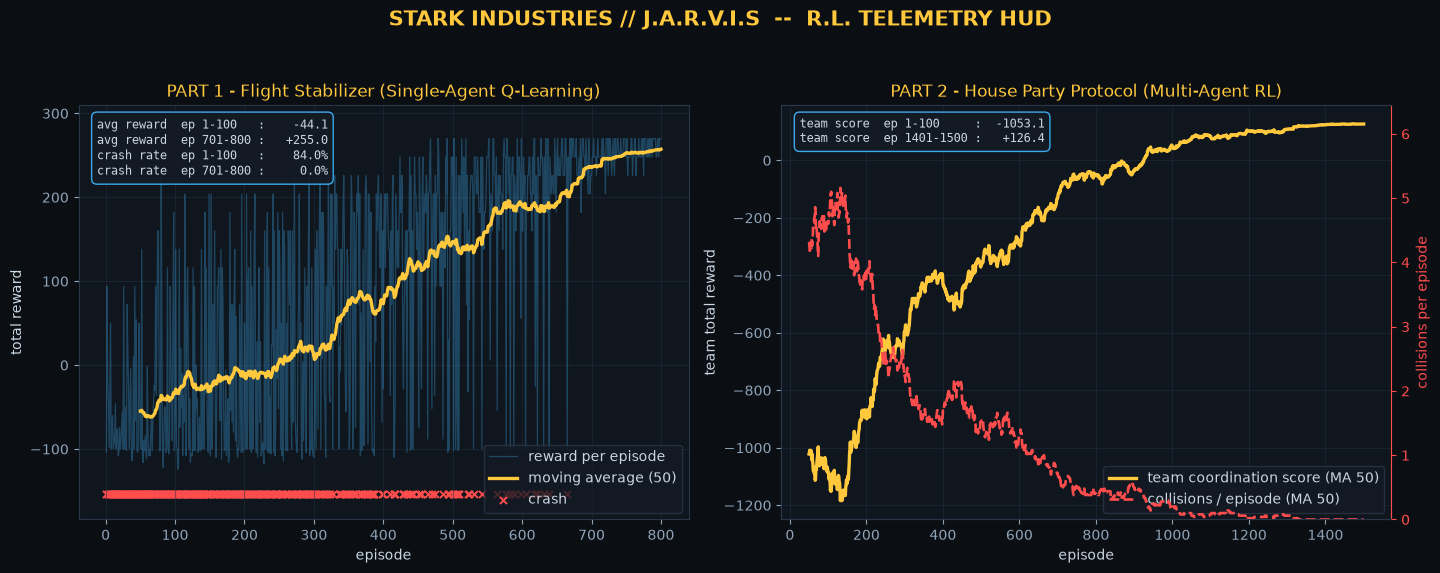

In [17]:
plot_stark_dashboard(rewards1, crashes1, team2, coll2)

### 🎮 STARK ARCADE — حالا خودت بازی کن!

فایل HTML مستقل ساخته می‌شود (همه‌ی جدول‌های Q داخلش پخته شده):

- **🎓 ACADEMY** — همان درس‌های این نوت‌بوک، تعاملی و کلیک‌خور
- **🛩 M1** — تماشای جارویس یا خودت خلبان شو و امتیازت را با AI مقایسه کن
- **🚀 M2** — رادار چندعامله با Pause/Step/Speed

> برای ارائه: `build_game_html(Q1, Qs2, open_browser=True)`

In [18]:
from stark_rl_game import build_game_html
from IPython.display import HTML

game_path = build_game_html(Q1, Qs2)
HTML(open(game_path, encoding="utf-8").read())

🎮 STARK RL ARCADE written to: C:\Users\Ashkan\Reinforcement Learning\stark_rl_game.html


---

## 🎓 فارغ‌التحصیل شدی!

چیزی که دیدی:
- حلقه‌ی عامل-محیط: اکشن → پاداش + وضعیت جدید
- جدول Q: ۲۷ حافظه‌ی «چقدر خوب بود؟» + معادله‌ی بلمن برای پرکردنش
- ε: اول کاوش، بعد بهره‌برداری
- چندعامله: مغزهای جدا + رادار + پاداش تیمی

**"I am Iron Man."** 🦾